# Credit Scoring with Machine Learning (German Credit Dataset)

**Goal:** predict whether a loan applicant is a **good** or **bad** credit risk using
Logistic Regression, a Decision Tree and a Random Forest, and compare them honestly.

> ⚠️ **Educational project only.** Nothing here is a real lending decision or a guarantee
> of repayment. See the *Responsible AI* section for why.

**How to read this notebook:** every section starts with a short plain-English explanation,
followed by the code that does the work. Run the cells from top to bottom
(*Runtime → Run all* in Colab).

## 0. Setup
We import the libraries, fix a **random seed** (so results are reproducible) and create
folders for data and outputs.

In [1]:
import os, json, urllib.request, warnings
from IPython.display import display   # lets display() also work in a plain .py script
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

os.makedirs("data", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)

def save_fig(name):
    """Save the current figure to outputs/figures and show it."""
    plt.tight_layout()
    plt.savefig(f"outputs/figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Python libraries loaded. scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Python libraries loaded. scikit-learn 1.8.0 | pandas 3.0.2


## 1. Dataset collection and understanding

**Source:** the *Statlog (German Credit Data)* dataset, created by Prof. Hans Hofmann and
published in the UCI Machine Learning Repository
(<https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data>).
It describes **1,000 loan applicants** from a German bank with **20 input features**
(e.g. checking-account status, loan amount, duration, savings, employment, age).

**Download:** the code below downloads the original data file from a public GitHub mirror
(the UCI server can also be used: `https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data`,
which is space-separated instead of comma-separated). If the download fails, download the file manually
and save it as `data/german_credit_raw.csv`.

**Target variable (original coding):** `1 = good credit`, `2 = bad credit`.

**Our definition (important!):** we recode it so that the *positive class* is the **risky** one:

| `default_risk` | Meaning |
|---|---|
| **0** | Good credit – applicant is expected to repay |
| **1** | **Bad credit – applicant is a credit risk (positive class)** |

Making "bad credit" the positive class means *recall* answers the natural business question
"**of all the truly risky applicants, how many did we catch?**".

The raw file stores categories as codes such as `A11`. We decode them to readable text using
the dataset's official documentation.

In [2]:
DATA_URL  = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/german.csv"
DATA_PATH = "data/german_credit_raw.csv"

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

COLUMNS = ["status", "duration", "credit_history", "purpose", "credit_amount", "savings",
           "employment", "installment_rate", "personal_status_sex", "other_debtors",
           "present_residence", "property", "age", "other_installment_plans", "housing",
           "number_credits", "job", "people_liable", "telephone", "foreign_worker", "target_raw"]

# Official UCI code book -> readable labels
CODE_MAPS = {
    "status": {"A11": "checking_<0DM", "A12": "checking_0-200DM", "A13": "checking_>=200DM", "A14": "no_checking_account"},
    "credit_history": {"A30": "no_credits_or_all_paid", "A31": "all_paid_at_this_bank", "A32": "existing_paid_duly",
                       "A33": "past_delay", "A34": "critical_or_other_credits"},
    "purpose": {"A40": "car_new", "A41": "car_used", "A42": "furniture", "A43": "radio_tv", "A44": "appliances",
                "A45": "repairs", "A46": "education", "A47": "vacation", "A48": "retraining", "A49": "business", "A410": "other"},
    "savings": {"A61": "<100DM", "A62": "100-500DM", "A63": "500-1000DM", "A64": ">=1000DM", "A65": "unknown_or_none"},
    "employment": {"A71": "unemployed", "A72": "<1yr", "A73": "1-4yrs", "A74": "4-7yrs", "A75": ">=7yrs"},
    "personal_status_sex": {"A91": "male_divorced_sep", "A92": "female_div_sep_married", "A93": "male_single",
                            "A94": "male_married_widowed", "A95": "female_single"},
    "other_debtors": {"A101": "none", "A102": "co_applicant", "A103": "guarantor"},
    "property": {"A121": "real_estate", "A122": "savings_agreement_or_insurance", "A123": "car_or_other", "A124": "unknown_or_none"},
    "other_installment_plans": {"A141": "bank", "A142": "stores", "A143": "none"},
    "housing": {"A151": "rent", "A152": "own", "A153": "free"},
    "job": {"A171": "unemployed_unskilled_nonresident", "A172": "unskilled_resident", "A173": "skilled", "A174": "management_highly_qualified"},
    "telephone": {"A191": "none", "A192": "yes"},
    "foreign_worker": {"A201": "yes", "A202": "no"},
}

raw = pd.read_csv(DATA_PATH, header=None, names=COLUMNS)
df = raw.copy()
for col, mapping in CODE_MAPS.items():
    df[col] = raw[col].map(mapping)
    assert df[col].notna().all(), f"Unmapped code found in {col}"

# Target: 1 = BAD credit (positive class), 0 = GOOD credit
df["default_risk"] = (raw["target_raw"] == 2).astype(int)
df = df.drop(columns="target_raw")
df.head()

,status,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,default_risk
0,checking_<0DM,6,critical_or_other_credits,radio_tv,1169,unknown_or_none,>=7yrs,4,male_single,none,...,real_estate,67,none,own,2,skilled,1,yes,yes,0
1,checking_0-200DM,48,existing_paid_duly,radio_tv,5951,<100DM,1-4yrs,2,female_div_sep_married,none,...,real_estate,22,none,own,1,skilled,1,none,yes,1
2,no_checking_account,12,critical_or_other_credits,education,2096,<100DM,4-7yrs,2,male_single,none,...,real_estate,49,none,own,1,unskilled_resident,2,none,yes,0
3,checking_<0DM,42,existing_paid_duly,furniture,7882,<100DM,4-7yrs,2,male_single,guarantor,...,savings_agreement_or_insurance,45,none,free,1,skilled,2,none,yes,0
4,checking_<0DM,24,past_delay,car_new,4870,<100DM,1-4yrs,3,male_single,none,...,unknown_or_none,53,none,free,2,skilled,2,none,yes,1


### 1.1 First look: shape, columns, data types, statistics, missing values

In [3]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:\n", list(df.columns))
print("\nData types:")
print(df.dtypes.to_string())

Shape (rows, columns): (1000, 21)

Column names:
 ['status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings', 'employment', 'installment_rate', 'personal_status_sex', 'other_debtors', 'present_residence', 'property', 'age', 'other_installment_plans', 'housing', 'number_credits', 'job', 'people_liable', 'telephone', 'foreign_worker', 'default_risk']

Data types:
status                       str
duration                   int64
credit_history               str
purpose                      str
credit_amount              int64
savings                      str
employment                   str
installment_rate           int64
personal_status_sex          str
other_debtors                str
present_residence          int64
property                     str
age                        int64
other_installment_plans      str
housing                      str
number_credits             int64
job                          str
people_liable              int64
telephone             

In [4]:
print("Summary statistics (numeric columns):")
display(df.describe().T.round(2))
print("\nSummary statistics (categorical columns):")
display(df.describe(include="object").T)

Summary statistics (numeric columns):


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0
present_residence,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0
number_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0
people_liable,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0
default_risk,1000.0,0.30,0.46,0.0,0.0,0.0,1.00,1.0



Summary statistics (categorical columns):


,count,unique,top,freq
status,1000,4,no_checking_account,394
credit_history,1000,5,existing_paid_duly,530
purpose,1000,10,radio_tv,280
savings,1000,5,<100DM,603
employment,1000,5,1-4yrs,339
personal_status_sex,1000,4,male_single,548
other_debtors,1000,3,none,907
property,1000,4,car_or_other,332
other_installment_plans,1000,3,none,814
housing,1000,3,own,713


In [5]:
print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

print("\nTarget class distribution:")
counts = df["default_risk"].value_counts().sort_index()
dist = pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)})
dist.index = ["0 = Good credit", "1 = Bad credit (positive class)"]
display(dist)

Total missing values: 0
Duplicate rows: 0

Target class distribution:


,count,percent
0 = Good credit,700,70.0
1 = Bad credit (positive class),300,30.0


**What we learn:**
* 1,000 rows, 20 original features (7 numeric, 13 categorical).
* **No missing values and no duplicate rows** in this file. (We still add imputers to the
  pipeline so the code is safe on messier data.)
* The classes are **imbalanced: 70% good vs 30% bad**. A model that always says "good credit"
  would already score 70% accuracy – which is why accuracy alone is misleading (see Section 6).

## 2. Feature engineering

Financial ratios can help a model, but **only if the dataset contains the ingredients**.
This dataset has *no income, no debt balances, no credit limit and no default counts*, so several
classic features are **not possible** and we deliberately do not invent them.

| Requested feature | Possible? | What we did |
|---|---|---|
| Debt-to-income ratio | ❌ No income/debt columns | Not created |
| Loan-to-income ratio | ❌ No income column | Not created (`installment_rate` is only a rough proxy) |
| Credit utilization | ❌ No credit-limit data | Not created |
| Number of previous defaults | ❌ Not recorded | Weak proxy: `history_delay_or_critical` |
| Payment-history indicator | ✅ via `credit_history` | `history_delay_or_critical` |

**Engineered features we *can* support:**

| Feature | Formula | Assumptions / limitations |
|---|---|---|
| `monthly_payment` | `credit_amount / duration` | Ignores interest, so the real payment is higher. |
| `payment_burden_index` | `monthly_payment × installment_rate` | `installment_rate` (1–4) is the bank's *installment rate as % of disposable income*, so this is a **relative index, not a true debt-to-income ratio**. |
| `has_multiple_credits` | `1` if `number_credits > 1` | Counts credits *at this bank* only. |
| `history_delay_or_critical` | `1` if history is `past_delay` or `critical_or_other_credits` | Intended as a rough "had payment trouble" flag; not an actual count of defaults. **EDA later shows it behaves *opposite* to intuition** (see Section 3), so treat it as an experiment, not a proven good feature. |
| `has_other_installment_plans` | `1` if plans with another bank/store | Doesn't tell us the size of those plans. |

These are computed **row by row** from the same applicant's data, so they cannot leak
information from the test set.

In [6]:
def engineer_features(data):
    """Add finance-inspired features that the dataset can genuinely support."""
    out = data.copy()
    out["monthly_payment"] = out["credit_amount"] / out["duration"]
    out["payment_burden_index"] = out["monthly_payment"] * out["installment_rate"]
    out["has_multiple_credits"] = (out["number_credits"] > 1).astype(int)
    out["history_delay_or_critical"] = out["credit_history"].isin(["past_delay", "critical_or_other_credits"]).astype(int)
    out["has_other_installment_plans"] = (out["other_installment_plans"] != "none").astype(int)
    return out

df_fe = engineer_features(df)
df_fe[["credit_amount", "duration", "installment_rate", "monthly_payment", "payment_burden_index",
       "has_multiple_credits", "history_delay_or_critical", "has_other_installment_plans"]].head()

,credit_amount,duration,installment_rate,monthly_payment,payment_burden_index,has_multiple_credits,history_delay_or_critical,has_other_installment_plans
0,1169,6,4,194.833333,779.333333,1,1,0
1,5951,48,2,123.979167,247.958333,0,0,0
2,2096,12,2,174.666667,349.333333,0,1,0
3,7882,42,2,187.666667,375.333333,0,0,0
4,4870,24,3,202.916667,608.750000,1,1,0


## 3. Exploratory data analysis (EDA)

EDA means *looking at the data with charts before modelling*, to spot patterns and problems.
(Age appears in EDA only to understand the data; it is **not** used as a model input – see Section 9.)

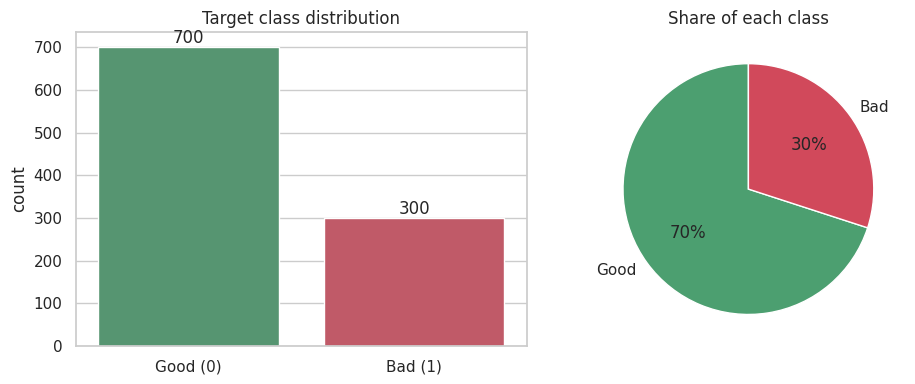

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x="default_risk", ax=axes[0], palette=["#4C9F70", "#D1495B"])
axes[0].set_xticklabels(["Good (0)", "Bad (1)"]); axes[0].set_title("Target class distribution"); axes[0].set_xlabel("")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
axes[1].pie(counts, labels=["Good", "Bad"], autopct="%1.0f%%", colors=["#4C9F70", "#D1495B"], startangle=90)
axes[1].set_title("Share of each class")
save_fig("01_target_distribution")

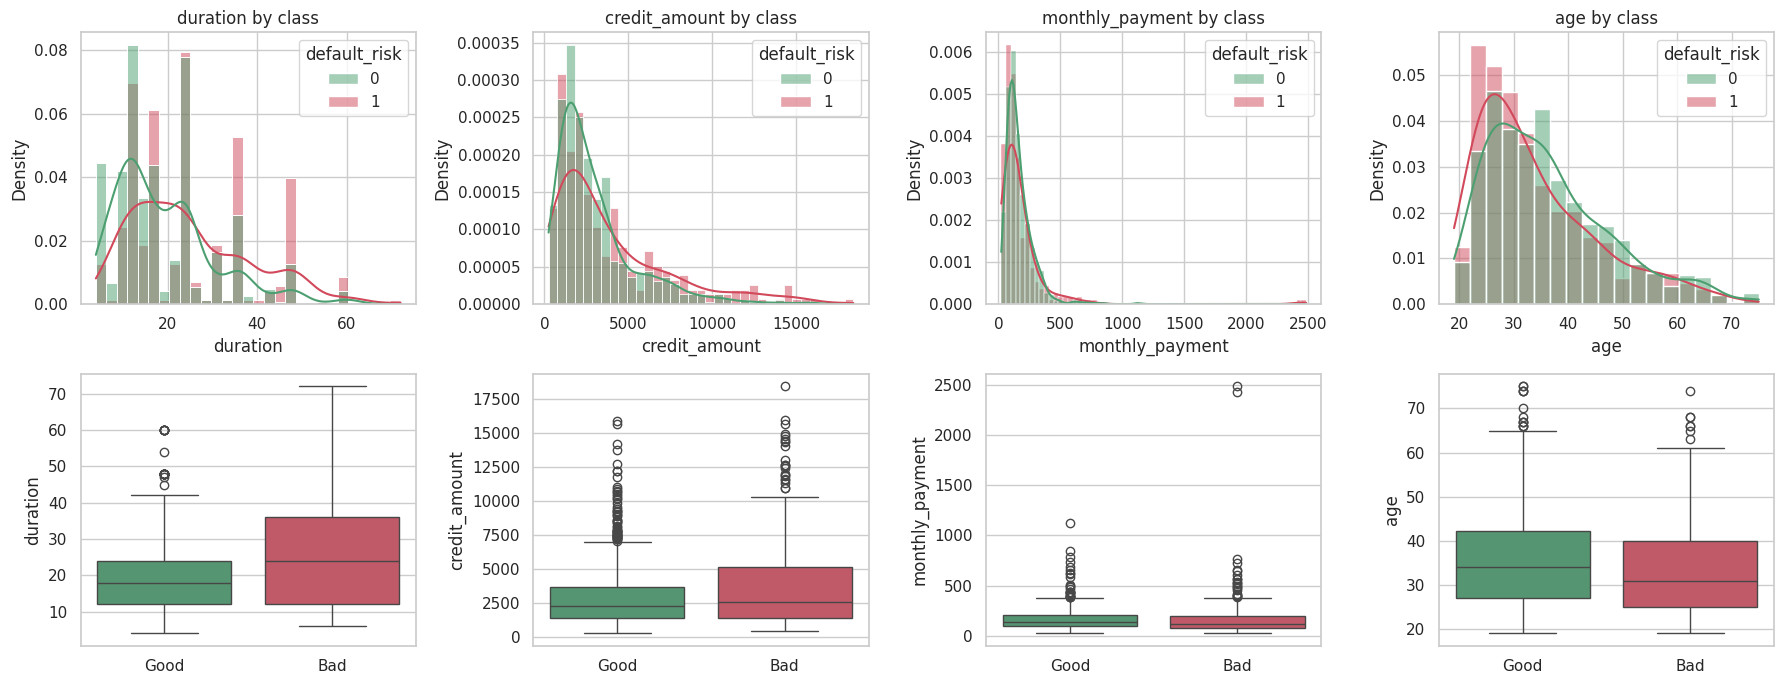

,duration,credit_amount,monthly_payment,age
default_risk,,,,
Good (median),18.0,2244.0,134.9,34.0
Bad (median),24.0,2574.5,121.1,31.0


In [8]:
num_plot = ["duration", "credit_amount", "monthly_payment", "age"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(num_plot):
    sns.histplot(data=df_fe, x=col, hue="default_risk", kde=True, stat="density", common_norm=False,
                 palette=["#4C9F70", "#D1495B"], ax=axes[0, i])
    axes[0, i].set_title(f"{col} by class")
    sns.boxplot(data=df_fe, x="default_risk", y=col, palette=["#4C9F70", "#D1495B"], ax=axes[1, i])
    axes[1, i].set_xticklabels(["Good", "Bad"]); axes[1, i].set_xlabel("")
save_fig("02_numeric_features_by_class")

display(df_fe.groupby("default_risk")[["duration", "credit_amount", "monthly_payment", "age"]].median().round(1)
        .rename(index={0: "Good (median)", 1: "Bad (median)"}))

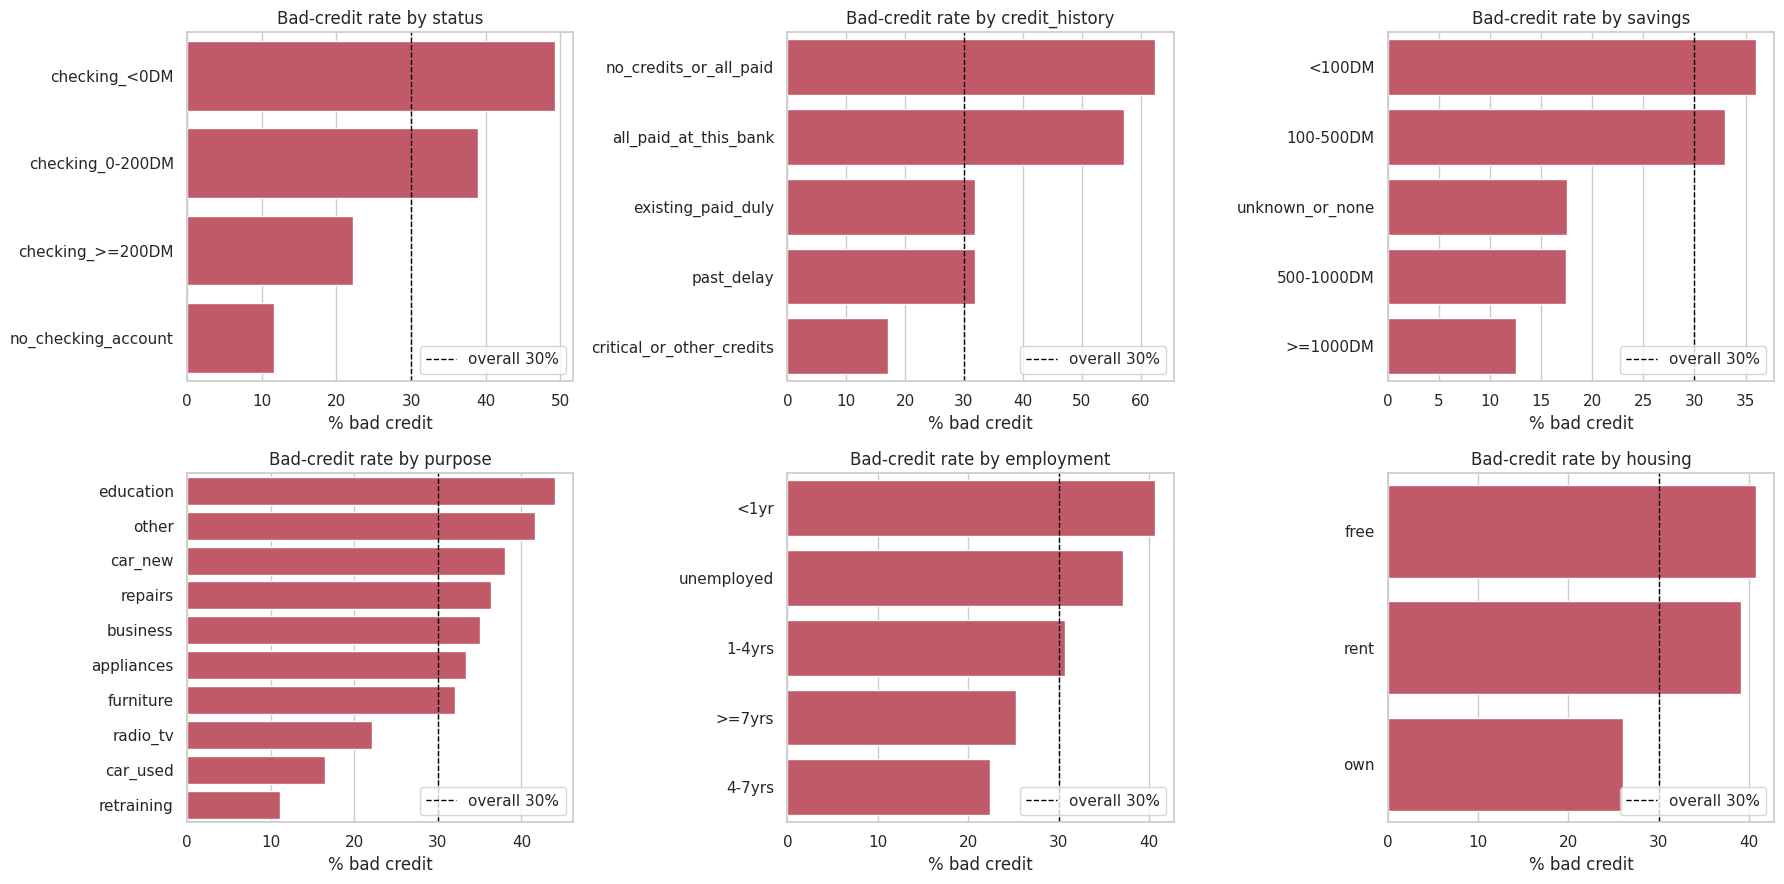


Bad-credit rate (%) by status


,rate,n
status,,
checking_<0DM,49.3,274
checking_0-200DM,39.0,269
checking_>=200DM,22.2,63
no_checking_account,11.7,394



Bad-credit rate (%) by credit_history


,rate,n
credit_history,,
no_credits_or_all_paid,62.5,40
all_paid_at_this_bank,57.1,49
existing_paid_duly,31.9,530
past_delay,31.8,88
critical_or_other_credits,17.1,293



Bad-credit rate (%) by savings


,rate,n
savings,,
<100DM,36.0,603
100-500DM,33.0,103
500-1000DM,17.5,63
unknown_or_none,17.5,183
>=1000DM,12.5,48


In [9]:
cat_plot = ["status", "credit_history", "savings", "purpose", "employment", "housing"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cat_plot):
    rate = df.groupby(col)["default_risk"].agg(["mean", "size"]).sort_values("mean", ascending=False)
    sns.barplot(x=rate["mean"] * 100, y=rate.index, color="#D1495B", ax=ax)
    ax.axvline(df["default_risk"].mean() * 100, color="black", ls="--", lw=1, label="overall 30%")
    ax.set_title(f"Bad-credit rate by {col}"); ax.set_xlabel("% bad credit"); ax.set_ylabel("")
    ax.legend(loc="lower right")
save_fig("03_bad_credit_rate_by_category")

for col in ["status", "credit_history", "savings"]:
    t = df.groupby(col)["default_risk"].agg(rate="mean", n="size")
    t["rate"] = (t["rate"] * 100).round(1)
    print(f"\nBad-credit rate (%) by {col}"); display(t.sort_values("rate", ascending=False))

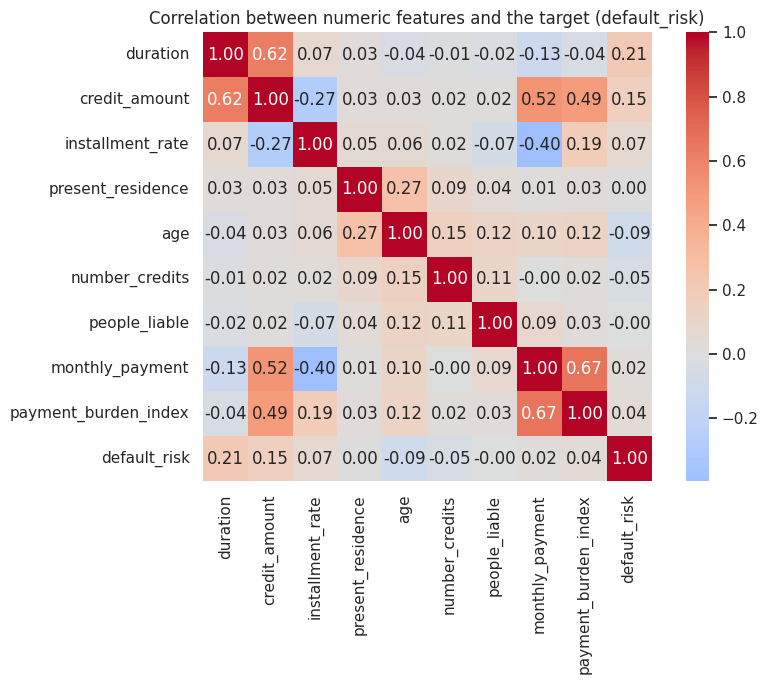

,correlation with default_risk
duration,0.215
credit_amount,0.155
installment_rate,0.072
payment_burden_index,0.045
monthly_payment,0.019
present_residence,0.003
people_liable,-0.003
number_credits,-0.046
age,-0.091


In [10]:
num_cols_eda = ["duration", "credit_amount", "installment_rate", "present_residence", "age", "number_credits",
                "people_liable", "monthly_payment", "payment_burden_index", "default_risk"]
plt.figure(figsize=(9, 7))
sns.heatmap(df_fe[num_cols_eda].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation between numeric features and the target (default_risk)")
save_fig("04_correlation_heatmap")
display(df_fe[num_cols_eda].corr()["default_risk"].drop("default_risk").sort_values(ascending=False).round(3).to_frame("correlation with default_risk"))

**Observations (simple language)** – the numbers behind these statements are printed above:
* Applicants who ask for **longer loans** and **larger amounts** are more often "bad" – a bigger,
  longer commitment carries more risk.
* The **checking-account status** is the strongest single signal: people with a negative or small
  checking balance are far more often bad credit than people with *no checking account* (which is the safest group
  in this data – a counter-intuitive pattern that shows why we must not over-interpret single features).
* **Credit history behaves counter-intuitively.** Applicants labelled *critical / other credits elsewhere* have the
  **lowest** bad-credit rate (17%), while those with *no credits / all paid* (62%) or *all paid at this bank* (57%) have the
  **highest** (small groups of 40 and 49 people). Likely explanation: people with a critical history who still got a loan
  were selected by the bank for other good reasons (selection bias). This is why our `history_delay_or_critical` flag is a weak idea here.
* Individual correlations with the target are modest (the strongest is `duration` at about 0.22), so no single number decides risk;
  models must combine many weak signals.
* **Our engineered payment features add little:** `monthly_payment` (corr ≈ 0.02) and `payment_burden_index` (≈ 0.05) are barely related
  to risk, and the *median* monthly payment is even slightly lower for bad applicants. We keep them for the assignment but do not claim they help.
* Younger applicants have a visibly higher bad-credit rate (see Section 9 for why we still do not use age as an input).

## 4. Data preprocessing and train/test split

**Avoiding data leakage:** if we scaled or encoded the *whole* dataset before splitting, information
from the test set would leak into training and our scores would look better than they should.
We therefore:

1. **Split first** (80% train / 20% test, `stratify=y` so both parts keep the 70/30 class mix, fixed seed).
2. Put every preprocessing step **inside a scikit-learn `Pipeline`**, so it is *fitted on training data only*
   and merely *applied* to the test data.

**Preprocessing steps**

| Column type | Steps |
|---|---|
| Numeric | median imputation → standard scaling (mean 0, std 1; matters for Logistic Regression) |
| Categorical | most-frequent imputation → one-hot encoding (`handle_unknown="ignore"`) |

**Duplicates & missing values:** none were found, so nothing is dropped; the imputers are a safety net.

**Sensitive attributes:** `personal_status_sex` (reveals sex), `age` and `foreign_worker` are **excluded from the model inputs**.
We keep them aside *only* to audit fairness afterwards (Section 9).

In [11]:
SENSITIVE = ["personal_status_sex", "age", "foreign_worker"]
TARGET = "default_risk"

df_model = df_fe.drop_duplicates().reset_index(drop=True)      # no duplicates here; kept for safety
X_all = df_model.drop(columns=[TARGET])
y = df_model[TARGET]
X = X_all.drop(columns=SENSITIVE)                              # model inputs (no protected attributes)
audit_info = X_all[SENSITIVE]                                  # used ONLY for the fairness audit

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = X.select_dtypes(exclude="number").columns.tolist()
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("Bad-credit share  train: {:.1%}  test: {:.1%}".format(y_train.mean(), y_test.mean()))
print("\nNumeric features    :", num_features)
print("Categorical features:", cat_features)

Train: (800, 22), Test: (200, 22)
Bad-credit share  train: 30.0%  test: 30.0%

Numeric features    : ['duration', 'credit_amount', 'installment_rate', 'present_residence', 'number_credits', 'people_liable', 'monthly_payment', 'payment_burden_index', 'has_multiple_credits', 'history_delay_or_critical', 'has_other_installment_plans']
Categorical features: ['status', 'credit_history', 'purpose', 'savings', 'employment', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone']


In [12]:
def make_preprocessor():
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", numeric, num_features),
                              ("cat", categorical, cat_features)])

def make_pipeline(estimator):
    return Pipeline([("prep", make_preprocessor()), ("model", estimator)])

## 5. Model development

We compare three classifiers (plus a "dummy" baseline that always predicts *good credit*):

* **Logistic Regression** – a simple, transparent model that adds up weighted evidence.
* **Decision Tree** – a flow-chart of yes/no questions. Easy to read but can memorise (overfit) the training data.
* **Random Forest** – many different trees voting together; usually more accurate and stable.

**Class imbalance:** only 30% of applicants are "bad", so we use `class_weight="balanced"`, which makes
mistakes on the minority (bad) class count more during training.

**Tuning & cross-validation:** `GridSearchCV` tries several hyperparameter settings (the "dials" of a model).
Each setting is scored with **5-fold stratified cross-validation** on the *training data only*
(the data is split in 5 parts; each part takes a turn as a mini test set). We optimise **ROC-AUC**, which
measures how well the model *ranks* risky applicants above safe ones, independent of any threshold.

In [13]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

search_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
        {"model__C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        {"model__max_depth": [3, 5, 7, None], "model__min_samples_leaf": [5, 10, 20]}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
        {"model__n_estimators": [200, 400], "model__max_depth": [5, 10, None], "model__min_samples_leaf": [1, 3, 5]}),
}

fitted = {}
for name, (estimator, grid) in search_spaces.items():
    gs = GridSearchCV(make_pipeline(estimator), grid, scoring="roc_auc", cv=skf, n_jobs=-1)
    gs.fit(X_train, y_train)
    fitted[name] = gs
    print(f"{name:20s} best CV ROC-AUC = {gs.best_score_:.3f} | best params = {gs.best_params_}")

baseline = make_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)

Logistic Regression  best CV ROC-AUC = 0.774 | best params = {'model__C': 0.1}


Decision Tree        best CV ROC-AUC = 0.698 | best params = {'model__max_depth': 7, 'model__min_samples_leaf': 20}


Random Forest        best CV ROC-AUC = 0.797 | best params = {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}


## 6. Model evaluation

**Positive class = 1 = bad credit.** All metrics below use this definition consistently
(`pos_label=1`, and ROC-AUC uses the predicted probability of class 1).

| Metric | Plain-English meaning | In credit-risk terms |
|---|---|---|
| **Accuracy** | share of all predictions that are right | can be high just by always predicting the majority class |
| **Precision** | of applicants *flagged risky*, how many truly were | low precision → many good customers wrongly rejected |
| **Recall** (sensitivity) | of truly risky applicants, how many we caught | low recall → many bad loans slip through |
| **F1-score** | balance (harmonic mean) of precision and recall | single number when both matter |
| **ROC-AUC** | chance the model gives a random bad applicant a higher risk score than a random good one (0.5 = coin flip, 1 = perfect) | threshold-free ranking quality |
| **Confusion matrix** | table of correct/incorrect predictions | shows the *types* of errors |

**The two kinds of mistakes**
* **False Negative (FN)** – a *risky* applicant is predicted *safe* → the bank approves a loan that is not repaid.
  Usually the **expensive** error (lost principal).
* **False Positive (FP)** – a *safe* applicant is predicted *risky* → the bank rejects a good customer
  (lost interest income, unfair to the applicant).

**Why accuracy alone misleads:** the dummy baseline below is "accurate" 70% of the time while catching **zero** bad applicants.

In [14]:
def evaluate(model, X_eval, y_eval, threshold=0.5):
    """All metrics for the positive class (1 = bad credit) at a chosen probability threshold."""
    proba = model.predict_proba(X_eval)[:, 1]            # probability of class 1 (bad credit)
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_eval, pred, labels=[0, 1]).ravel()
    return {
        "Accuracy":  accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, pos_label=1, zero_division=0),
        "Recall":    recall_score(y_eval, pred, pos_label=1),
        "F1-score":  f1_score(y_eval, pred, pos_label=1, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_eval, proba),
        "False-negative rate": fn / (fn + tp),           # risky applicants we missed
        "False-positive rate": fp / (fp + tn),           # good applicants wrongly flagged
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }, proba, pred

results, probas, preds = {}, {}, {}
for name, gs in fitted.items():
    results[name], probas[name], preds[name] = evaluate(gs.best_estimator_, X_test, y_test)
results["Baseline (always 'good')"], _, _ = evaluate(baseline, X_test, y_test)

LABELS = ["Good credit (0)", "Bad credit (1)"]
for name in fitted:
    print("=" * 70); print(name, "- classification report on the TEST set (threshold 0.5)")
    print(classification_report(y_test, preds[name], target_names=LABELS, digits=3))

Logistic Regression - classification report on the TEST set (threshold 0.5)
                 precision    recall  f1-score   support

Good credit (0)      0.886     0.721     0.795       140
 Bad credit (1)      0.547     0.783     0.644        60

       accuracy                          0.740       200
      macro avg      0.716     0.752     0.720       200
   weighted avg      0.784     0.740     0.750       200

Decision Tree - classification report on the TEST set (threshold 0.5)
                 precision    recall  f1-score   support

Good credit (0)      0.789     0.614     0.691       140
 Bad credit (1)      0.407     0.617     0.490        60

       accuracy                          0.615       200
      macro avg      0.598     0.615     0.590       200
   weighted avg      0.674     0.615     0.631       200

Random Forest - classification report on the TEST set (threshold 0.5)
                 precision    recall  f1-score   support

Good credit (0)      0.828     0.857

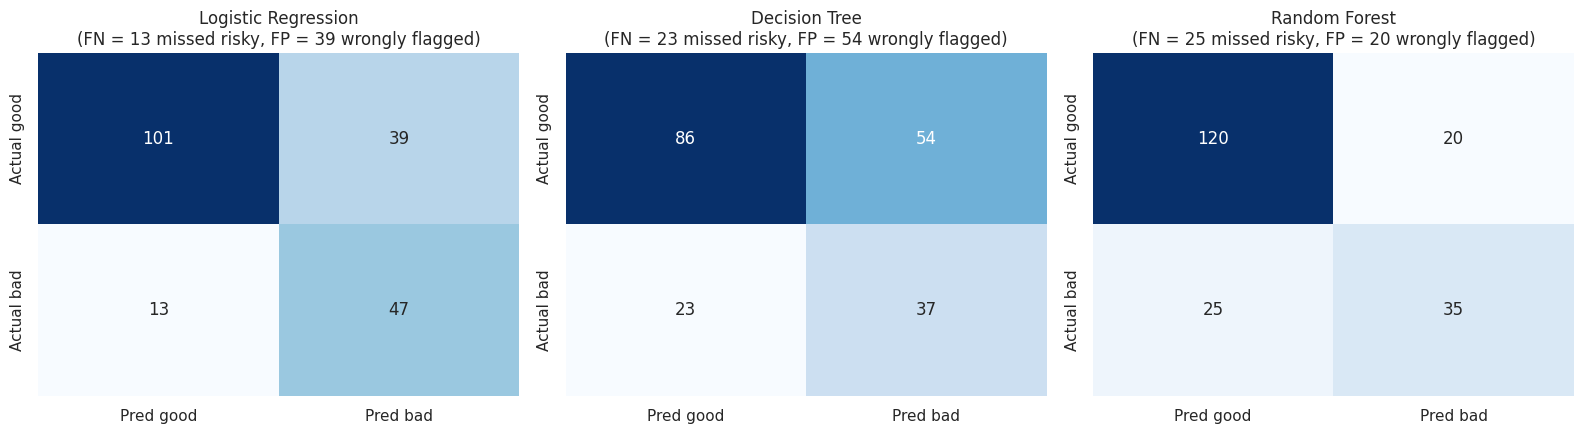

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, fitted):
    cm = confusion_matrix(y_test, preds[name], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred good", "Pred bad"], yticklabels=["Actual good", "Actual bad"])
    ax.set_title(f"{name}\n(FN = {cm[1,0]} missed risky, FP = {cm[0,1]} wrongly flagged)")
save_fig("05_confusion_matrices")

## 7. Model comparison and selection

### 7.1 Comparison table (default threshold 0.5)

In [16]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "False-negative rate", "False-positive rate"]
comparison = pd.DataFrame(results).T[metric_cols].astype(float).round(3)
comparison.insert(0, "CV ROC-AUC (train)", [round(fitted[n].best_score_, 3) if n in fitted else np.nan for n in comparison.index])
comparison.to_csv("outputs/model_comparison.csv")
display(comparison)

,CV ROC-AUC (train),Accuracy,Precision,Recall,F1-score,ROC-AUC,False-negative rate,False-positive rate
Logistic Regression,0.774,0.740,0.547,0.783,0.644,0.805,0.217,0.279
Decision Tree,0.698,0.615,0.407,0.617,0.490,0.677,0.383,0.386
Random Forest,0.797,0.775,0.636,0.583,0.609,0.791,0.417,0.143
Baseline (always 'good'),NaN,0.700,0.000,0.000,0.000,0.500,1.000,0.000


### 7.2 ROC curves

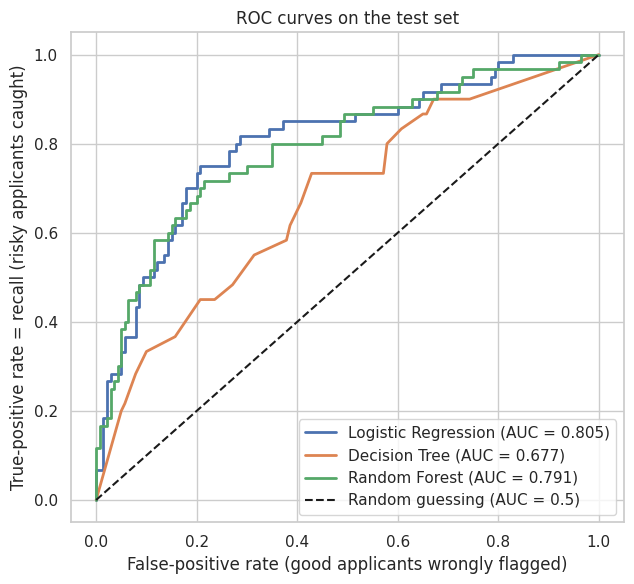

In [17]:
plt.figure(figsize=(6.5, 6))
for name in fitted:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing (AUC = 0.5)")
plt.xlabel("False-positive rate (good applicants wrongly flagged)")
plt.ylabel("True-positive rate = recall (risky applicants caught)")
plt.title("ROC curves on the test set"); plt.legend(loc="lower right")
save_fig("06_roc_curves")

### 7.3 Choosing a model with *credit-risk goals*, not just accuracy

Lowering the probability threshold flags more applicants as risky: **recall goes up, precision goes down**.
Where to put the threshold depends on the cost of each error. The original dataset documentation
suggests a **cost matrix in which approving a bad applicant (FN) is 5× worse than rejecting a good one (FP)**.
We use that ratio as an *illustrative assumption* (a real bank would use its own numbers):

> `cost = 5 × FN + 1 × FP`

To avoid peeking at the test set, we:
1. get **out-of-fold probabilities** on the training data (each applicant is scored by a model that never saw them),
2. pick, for each model, the threshold that minimises the cost on those out-of-fold predictions,
3. **select the model with the lowest cost per applicant** and only then look at the test set.

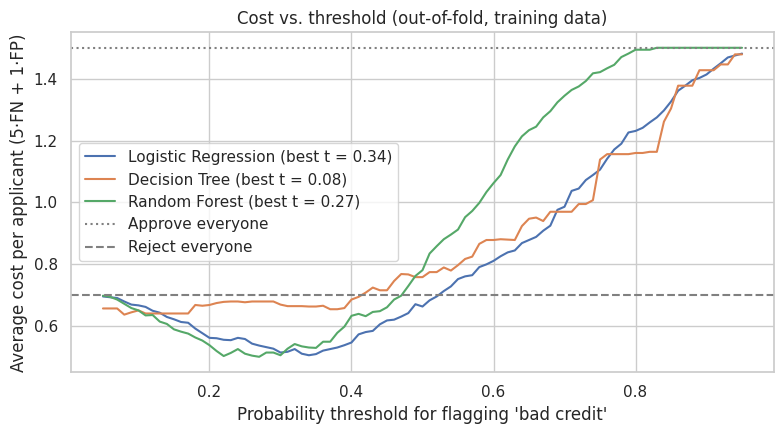

,best threshold,out-of-fold cost / applicant
Logistic Regression,0.34,0.506
Decision Tree,0.08,0.638
Random Forest,0.27,0.501



Selected model (lowest cross-validated cost): Random Forest  | threshold = 0.27


In [18]:
COST_FN, COST_FP = 5, 1
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)

def cost_curve(y_true, proba):
    costs = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        fp = ((pred == 1) & (y_true == 0)).sum(); fn = ((pred == 0) & (y_true == 1)).sum()
        costs.append((COST_FN * fn + COST_FP * fp) / len(y_true))
    return np.array(costs)

oof_proba = {n: cross_val_predict(gs.best_estimator_, X_train, y_train, cv=skf, method="predict_proba")[:, 1]
             for n, gs in fitted.items()}

chosen_threshold, oof_cost = {}, {}
plt.figure(figsize=(8, 4.5))
for n in fitted:
    c = cost_curve(y_train.values, oof_proba[n])
    chosen_threshold[n] = float(thresholds[c.argmin()]); oof_cost[n] = float(c.min())
    plt.plot(thresholds, c, label=f"{n} (best t = {chosen_threshold[n]:.2f})")
plt.axhline(COST_FN * y_train.mean(), color="gray", ls=":", label="Approve everyone")
plt.axhline(COST_FP * (1 - y_train.mean()), color="gray", ls="--", label="Reject everyone")
plt.xlabel("Probability threshold for flagging 'bad credit'"); plt.ylabel("Average cost per applicant (5·FN + 1·FP)")
plt.title("Cost vs. threshold (out-of-fold, training data)"); plt.legend()
save_fig("07_cost_vs_threshold")

selection = pd.DataFrame({"best threshold": chosen_threshold, "out-of-fold cost / applicant": oof_cost}).round(3)
display(selection)
best_name = min(oof_cost, key=oof_cost.get)
best_threshold = chosen_threshold[best_name]
print(f"\nSelected model (lowest cross-validated cost): {best_name}  | threshold = {best_threshold:.2f}")

In [19]:
rows = {}
for n, gs in fitted.items():
    r, _, _ = evaluate(gs.best_estimator_, X_test, y_test, threshold=chosen_threshold[n])
    r["Test cost / applicant"] = (COST_FN * r["FN"] + COST_FP * r["FP"]) / len(y_test)
    rows[f"{n} @ t={chosen_threshold[n]:.2f}"] = r
r05, _, _ = evaluate(fitted[best_name].best_estimator_, X_test, y_test, 0.5)
r05["Test cost / applicant"] = (COST_FN * r05["FN"] + COST_FP * r05["FP"]) / len(y_test)
rows[f"{best_name} @ t=0.50 (default)"] = r05
tuned = pd.DataFrame(rows).T[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "FN", "FP", "Test cost / applicant"]].astype(float).round(3)
tuned.to_csv("outputs/model_comparison_tuned_threshold.csv")
display(tuned)
print("Reference: approving everyone costs", round(COST_FN * y_test.mean(), 3), "per applicant; rejecting everyone costs", round(1 - y_test.mean(), 3))

# How uncertain is the test AUC? (200 test rows is small) -> bootstrap 95% interval
rng = np.random.default_rng(SEED)
yt = y_test.values; pb = probas[best_name]
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[idx])) == 2:
        boot.append(roc_auc_score(yt[idx], pb[idx]))
auc_ci = np.percentile(boot, [2.5, 97.5])
print(f"{best_name}: test ROC-AUC = {results[best_name]['ROC-AUC']:.3f}, 95% bootstrap interval = [{auc_ci[0]:.3f}, {auc_ci[1]:.3f}]")

,Accuracy,Precision,Recall,F1-score,ROC-AUC,FN,FP,Test cost / applicant
Logistic Regression @ t=0.34,0.570,0.400,0.867,0.547,0.805,8.0,78.0,0.590
Decision Tree @ t=0.08,0.450,0.342,0.900,0.495,0.677,6.0,104.0,0.670
Random Forest @ t=0.27,0.555,0.393,0.883,0.544,0.791,7.0,82.0,0.585
Random Forest @ t=0.50 (default),0.775,0.636,0.583,0.609,0.791,25.0,20.0,0.725


Reference: approving everyone costs 1.5 per applicant; rejecting everyone costs 0.7


Random Forest: test ROC-AUC = 0.791, 95% bootstrap interval = [0.715, 0.864]


**How to read the two tables above**
* At the default threshold 0.5 the Random Forest has the best accuracy and precision, but it **misses 42% of risky applicants** (FN rate).
  Logistic Regression catches more (recall 78%) but wrongly flags more good applicants.
* Using the 5:1 cost, the best threshold drops to about 0.27: the Random Forest then catches ~88% of risky applicants but also
  **flags roughly two-thirds of everyone** (precision ≈ 39%). It is only modestly cheaper than the trivial strategy *"reject everyone"*
  (0.585 vs 0.700 per applicant) – a sign of how hard this problem is with these features and how heavy a 5:1 penalty is.
* **Random Forest and Logistic Regression are essentially tied** (cross-validated cost 0.501 vs 0.506; test cost 0.585 vs 0.590).
  We pick the Random Forest because the rule was "lowest cross-validated cost", but a simple, transparent Logistic Regression
  would be an equally defensible choice – in a regulated setting its explainability might even make it the better one.
* The Decision Tree is clearly the weakest model. Note its default-threshold accuracy (61.5%) is even *below* the 70% baseline –
  accuracy is not a safe yardstick.

**Trade-offs in plain words**
* **Higher precision** (fewer good customers rejected) usually means **lower recall** (more bad loans approved).
* If missing a bad applicant is far more costly than rejecting a good one, we accept lower precision to get
  higher recall, i.e. a *lower* threshold than 0.5.
* The test set has only 200 applicants (60 bad), so every number above is **uncertain** – the bootstrap interval
  shows how much the AUC could change just by luck. Differences of a few hundredths between models are **not** reliable.

> **This does not prove the model is fit for real lending.** A good score on one small, old, German
> dataset says nothing about performance on today's applicants, other populations, or under law.

## 8. Prediction demonstration (educational only)

`predict_applicant()` takes the applicant's financial information, builds the engineered features,
runs the selected pipeline and returns the predicted class and the estimated **probability of bad credit**.

> 🎓 **Educational demo.** This output is *not* a financial decision, an approval/denial,
> or a guarantee of repayment. The probability is a model estimate learned from 800 historical rows.

In [20]:
final_model = fitted[best_name].best_estimator_
final_threshold = best_threshold

def predict_applicant(applicant, model=final_model, threshold=final_threshold):
    """applicant: dict with the raw (decoded) input features. Returns a dict with class + probability."""
    required = ["status", "duration", "credit_history", "purpose", "credit_amount", "savings", "employment",
                "installment_rate", "other_debtors", "present_residence", "property", "other_installment_plans",
                "housing", "number_credits", "job", "people_liable", "telephone"]
    missing = [k for k in required if k not in applicant]
    if missing:
        raise ValueError(f"Missing applicant fields: {missing}")
    row = engineer_features(pd.DataFrame([applicant]))[X_train.columns]
    p_bad = float(model.predict_proba(row)[0, 1])
    flagged = p_bad >= threshold
    return {"estimated_probability_bad_credit": round(p_bad, 3),
            "threshold_used": threshold,
            "predicted_class": "1 = BAD credit risk (flagged)" if flagged else "0 = GOOD credit (not flagged)"}

def explain(result):
    print("-" * 70)
    print("EDUCATIONAL EXAMPLE - NOT A REAL LENDING DECISION")
    print(f"Predicted class                    : {result['predicted_class']}")
    print(f"Estimated probability of bad credit: {result['estimated_probability_bad_credit']:.1%}")
    print(f"Decision threshold                 : {result['threshold_used']:.2f}")
    print("Meaning: among historical applicants with a similar profile, the model estimates this chance of a bad outcome.")
    print("It is a statistical estimate, not a prediction about this specific person's behaviour.")
    print("-" * 70)

example_low_risk = dict(status="no_checking_account", duration=12, credit_history="existing_paid_duly", purpose="furniture",
                        credit_amount=1500, savings=">=1000DM", employment=">=7yrs", installment_rate=2,
                        other_debtors="none", present_residence=3, property="real_estate", other_installment_plans="none",
                        housing="own", number_credits=1, job="skilled", people_liable=1, telephone="yes")
example_high_risk = dict(status="checking_<0DM", duration=48, credit_history="past_delay", purpose="car_used",
                         credit_amount=9000, savings="<100DM", employment="<1yr", installment_rate=4,
                         other_debtors="none", present_residence=1, property="unknown_or_none", other_installment_plans="bank",
                         housing="rent", number_credits=2, job="unskilled_resident", people_liable=1, telephone="none")
print("Example A (short, small loan, strong savings):"); explain(predict_applicant(example_low_risk))
print("Example B (long, large loan, negative checking balance):"); explain(predict_applicant(example_high_risk))

Example A (short, small loan, strong savings):
----------------------------------------------------------------------
EDUCATIONAL EXAMPLE - NOT A REAL LENDING DECISION
Predicted class                    : 0 = GOOD credit (not flagged)
Estimated probability of bad credit: 5.9%
Decision threshold                 : 0.27
Meaning: among historical applicants with a similar profile, the model estimates this chance of a bad outcome.
It is a statistical estimate, not a prediction about this specific person's behaviour.
----------------------------------------------------------------------
Example B (long, large loan, negative checking balance):
----------------------------------------------------------------------
EDUCATIONAL EXAMPLE - NOT A REAL LENDING DECISION
Predicted class                    : 1 = BAD credit risk (flagged)
Estimated probability of bad credit: 70.0%
Decision threshold                 : 0.27
Meaning: among historical applicants with a similar profile, the model estimates t

## 9. Explainability and Responsible AI

### 9.1 Which features matter most?
**Permutation importance:** shuffle one feature at a time on the test set and see how much the ROC-AUC drops.
A big drop = the model relied on that feature. It works for any model and uses the *original* columns
(not the one-hot pieces). For the transparent Logistic Regression we additionally show its coefficients.

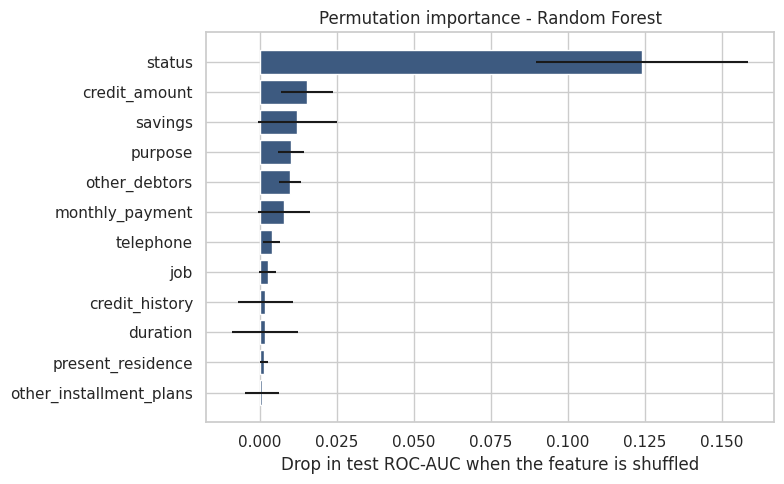

,feature,importance,std
0,status,0.1240,0.0345
4,credit_amount,0.0153,0.0085
5,savings,0.0121,0.0128
3,purpose,0.0100,0.0043
8,other_debtors,0.0098,0.0035
17,monthly_payment,0.0079,0.0084
16,telephone,0.0038,0.0027
14,job,0.0025,0.0028
2,credit_history,0.0017,0.0090
1,duration,0.0016,0.0107


In [21]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std}) \
        .sort_values("importance", ascending=False)
top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="#3D5A80")
plt.xlabel("Drop in test ROC-AUC when the feature is shuffled")
plt.title(f"Permutation importance - {best_name}")
save_fig("08_permutation_importance")
imp.to_csv("outputs/permutation_importance.csv", index=False)
display(imp.head(10).round(4))

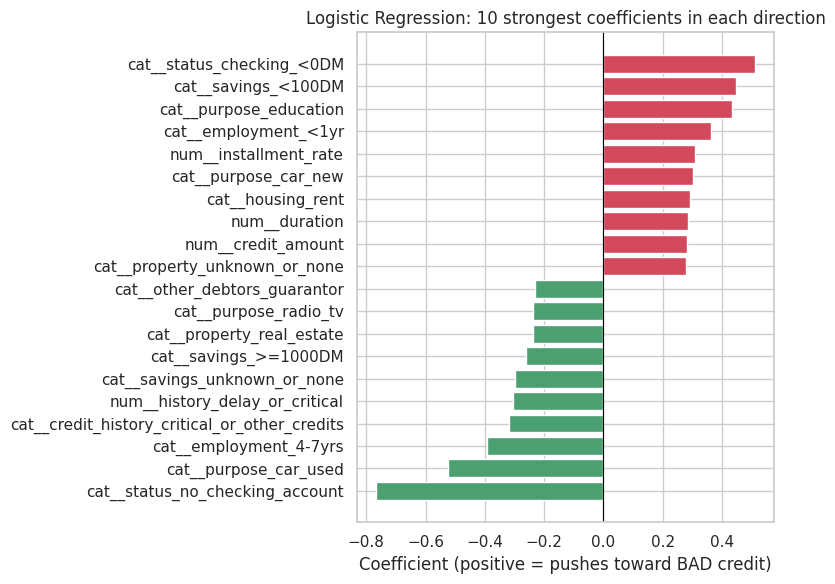

In [22]:
lr_pipe = fitted["Logistic Regression"].best_estimator_
names = lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=names).sort_values()
extreme = pd.concat([coefs.head(10), coefs.tail(10)])
plt.figure(figsize=(8, 6))
plt.barh(extreme.index, extreme.values, color=["#4C9F70" if v < 0 else "#D1495B" for v in extreme.values])
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Coefficient (positive = pushes toward BAD credit)")
plt.title("Logistic Regression: 10 strongest coefficients in each direction")
save_fig("09_logistic_regression_coefficients")

### 9.2 Fairness check (audit using attributes the model never saw)

Even though `age`, sex (from `personal_status_sex`) and `foreign_worker` are **not inputs**, other features can act as
**proxies** for them. We check whether the model treats groups very differently. Remember: group sizes in a
200-row test set are small, so differences can be noise – this is a *screening tool*, not proof of fairness or unfairness.

In [23]:
audit = audit_info.loc[X_test.index].copy()
audit["sex"] = audit["personal_status_sex"].map(lambda s: "female" if s.startswith("female") else "male")
audit["age_group"] = pd.cut(audit["age"], bins=[0, 24, 39, 120], labels=["<25", "25-39", "40+"])
proba_best = final_model.predict_proba(X_test)[:, 1]
audit["actual_bad"] = y_test.values
audit["flagged"] = (proba_best >= final_threshold).astype(int)

def group_table(col):
    g = audit.groupby(col, observed=True)
    out = pd.DataFrame({
        "n": g.size(),
        "actual bad rate": g["actual_bad"].mean(),
        "flagged rate": g["flagged"].mean(),
        "recall (bad caught)": g.apply(lambda d: d.loc[d.actual_bad == 1, "flagged"].mean()),
        "false-positive rate": g.apply(lambda d: d.loc[d.actual_bad == 0, "flagged"].mean()),
    })
    return out.round(3)

for col in ["sex", "age_group", "foreign_worker"]:
    print(f"\nBy {col}:"); display(group_table(col))


By sex:


,n,actual bad rate,flagged rate,recall (bad caught),false-positive rate
sex,,,,,
female,61,0.328,0.705,0.85,0.634
male,139,0.288,0.662,0.90,0.566



By age_group:


,n,actual bad rate,flagged rate,recall (bad caught),false-positive rate
age_group,,,,,
<25,39,0.487,0.769,0.895,0.650
25-39,90,0.278,0.656,0.880,0.569
40+,71,0.225,0.648,0.875,0.582



By foreign_worker:


,n,actual bad rate,flagged rate,recall (bad caught),false-positive rate
foreign_worker,,,,,
no,6,0.167,0.50,1.000,0.400
yes,194,0.304,0.68,0.881,0.593


### 9.3 Responsible-AI discussion

**Bias & fairness**
* The data come from **one German bank in the 1990s**; the applicant pool, laws and economy are very different today.
  The past approvals that created the labels may themselves reflect human bias.
* Protected attributes (age, sex, nationality) are excluded from the inputs, but **proxies** (e.g. housing, job, employment length)
  can still encode them. "Fairness through unawareness" is not enough – hence the audit above.
* Lending is regulated (e.g. EU anti-discrimination law and the GDPR's rules on automated decisions; in the US the ECOA/Reg B);
  a real system would need formal fairness testing and an explanation for every declined applicant.

**Privacy**
* Credit data are highly personal. Real projects need consent, data minimisation, secure storage and access control.
  This dataset is anonymised and public, but similar data in practice are not.

**Data quality**
* Only 1,000 rows; some categories are rare; amounts are in old Deutsche Marks; there is no income, debt balance, or time dimension.
* Labels reflect *this bank's* idea of "bad credit", and applicants who were **rejected** are missing entirely (selection bias).

**Correlation is not causation**
* Feature importance says what the model *uses to predict*, not what *causes* default.
  For example, "no checking account" being low-risk does not mean closing your account makes you safer.

**Limitations of this model**
* Small test set → wide uncertainty (see the bootstrap interval); tuned on one random split.
* The 5:1 cost ratio is an assumption; probabilities are not formally *calibrated*.
* No evaluation over time (data drift) or across populations.

**Before any real-world use** a model like this would need: validation on recent, representative data;
calibration checks; out-of-time testing; fairness and legal/regulatory review; explainability for affected people;
human oversight; and continuous monitoring after deployment.

## 10. Save outputs

In [24]:
joblib.dump({"model": final_model, "threshold": final_threshold, "model_name": best_name,
             "feature_columns": list(X_train.columns)}, "outputs/credit_model.joblib")

summary = {
    "dataset": {"rows": int(len(df)), "bad_rate": float(df[TARGET].mean()), "missing": int(df.isna().sum().sum()),
                "duplicates": int(df.duplicated().sum())},
    "sklearn_version": sklearn.__version__,
    "seed": SEED,
    "best_params": {n: gs.best_params_ for n, gs in fitted.items()},
    "selected_model": best_name, "selected_threshold": final_threshold,
    "selected_test_auc_95ci": [float(auc_ci[0]), float(auc_ci[1])],
}
with open("outputs/results_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
print("\nSaved: outputs/model_comparison.csv, outputs/model_comparison_tuned_threshold.csv, outputs/permutation_importance.csv,")
print("       outputs/credit_model.joblib, outputs/results_summary.json and figures in outputs/figures/")

{
  "dataset": {
    "rows": 1000,
    "bad_rate": 0.3,
    "missing": 0,
    "duplicates": 0
  },
  "sklearn_version": "1.8.0",
  "seed": 42,
  "best_params": {
    "Logistic Regression": {
      "model__C": 0.1
    },
    "Decision Tree": {
      "model__max_depth": 7,
      "model__min_samples_leaf": 20
    },
    "Random Forest": {
      "model__max_depth": null,
      "model__min_samples_leaf": 3,
      "model__n_estimators": 400
    }
  },
  "selected_model": "Random Forest",
  "selected_threshold": 0.27,
  "selected_test_auc_95ci": [
    0.7153106789885766,
    0.8635170984733028
  ]
}

Saved: outputs/model_comparison.csv, outputs/model_comparison_tuned_threshold.csv, outputs/permutation_importance.csv,
       outputs/credit_model.joblib, outputs/results_summary.json and figures in outputs/figures/
